### IND320 project work part 1 
Name: Mina Johanne Askerød <br>
Date: .10.2026 <br>
GitHub link: https://github.com/Minajohanne/IND320_project_Minajohanne <br>
Streamlit link: https://ind320projectminajohanne.streamlit.app/<br>
Recording link: 


#### Import packages

In [1]:
import requests
import pandas as pd
import json 
import matplotlib.pyplot as plt
from pathlib import Path
import xml.etree.ElementTree as ET


##### Reservoir data from magasinstatisikk using direvt API 

In [2]:
# retrieving data from magasinstatistikk using an API 
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
response = requests.get(url)
print(response)

<Response [200]>


In [3]:

data = response.json()
data
type(data)
df = pd.DataFrame(data)
df.head()


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [4]:
df.describe()

,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,fyllingsgrad_forrige_uke,endring_fyllingsgrad
count,14913.000000,14913.000000,14913.000000,14913.000000,14913.000000,14913.000000,14913.000000,14913.000000
mean,2.333333,2010.383826,26.435124,0.618892,29.145860,18.141091,0.618891,0.000002
std,1.490762,9.167891,15.011609,0.214720,22.739069,15.963174,0.214709,0.031342
min,0.000000,1995.000000,1.000000,0.051653,6.003264,0.310089,0.051653,-0.242484
25%,1.000000,2002.000000,13.000000,0.456675,17.390587,7.325503,0.456715,-0.022364
50%,2.000000,2010.000000,26.000000,0.648049,23.237715,14.503712,0.648057,-0.007005
75%,3.000000,2018.000000,39.000000,0.801892,34.043590,22.202377,0.801822,0.016298
max,5.000000,2026.000000,53.000000,1.020072,87.437580,84.518060,1.020037,0.345632


In [5]:
df.shape

(14913, 11)

In [6]:
# map names dictionary
map_names = {
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "filling_level",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "filling_level_previous_week",
    "endring_fyllingsgrad": "change_in_filling_level"
}  

# map names
df = df.rename(columns=map_names)  

In [7]:
df["date"].head(10)

0    1995-09-03
1    2020-11-15
2    2011-08-28
3    1998-07-05
4    2011-03-27
5    2017-11-05
6    2000-11-26
7    2016-09-04
8    2023-08-13
9    2011-09-04
Name: date, dtype: str

In [8]:
# sort the dataframe by date
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(by="date", ascending=True)
df.head()

,date,area_type,area_number,iso_year,iso_week,filling_level,capacity_TWh,stored_energy_TWh,next_publication_date,filling_level_previous_week,change_in_filling_level
11338,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837
14493,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
9673,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643
7882,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
4579,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349


In [9]:
(df["next_publication_date"] == "0001-01-01T00:00:00").sum()

np.int64(11322)

In [10]:
placeholder = df[
    df["next_publication_date"] == "0001-01-01T00:00:00"
]

# Count placeholder dates per year
placeholder_counts = (
    placeholder.groupby("iso_year")
    .size()
    .reset_index(name="count")
)
placeholder_counts

,iso_year,count
0,1995,468
1,1996,468
2,1997,468
3,1998,477
4,1999,468
5,2000,468
6,2001,468
7,2002,468
8,2003,468
9,2004,477


The value "0001-01-01T00:00:00" in column "next_publication_date" does not represent a publication date, but seems to be a placeholder for missing publication dates. I therefore convert these values to NaT (not a time), which is pandas´representation of missing datetime values. 

In [11]:
# Replace placeholder dates with missing values
df["next_publication_date"] = df["next_publication_date"].replace(
    "0001-01-01T00:00:00",
    pd.NA
)

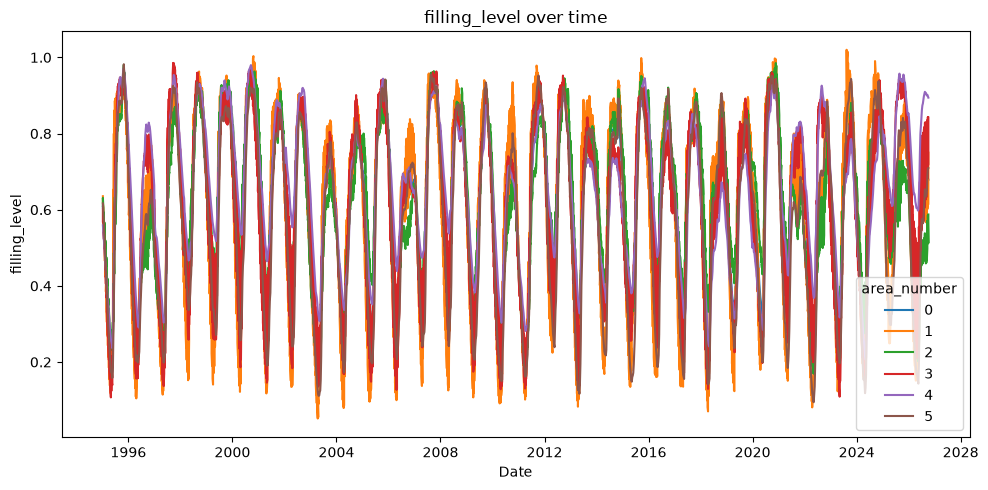

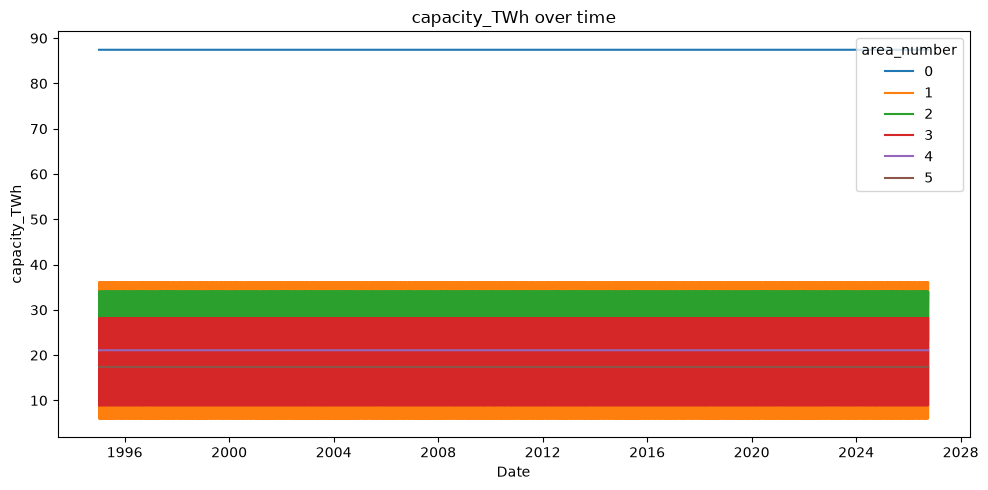

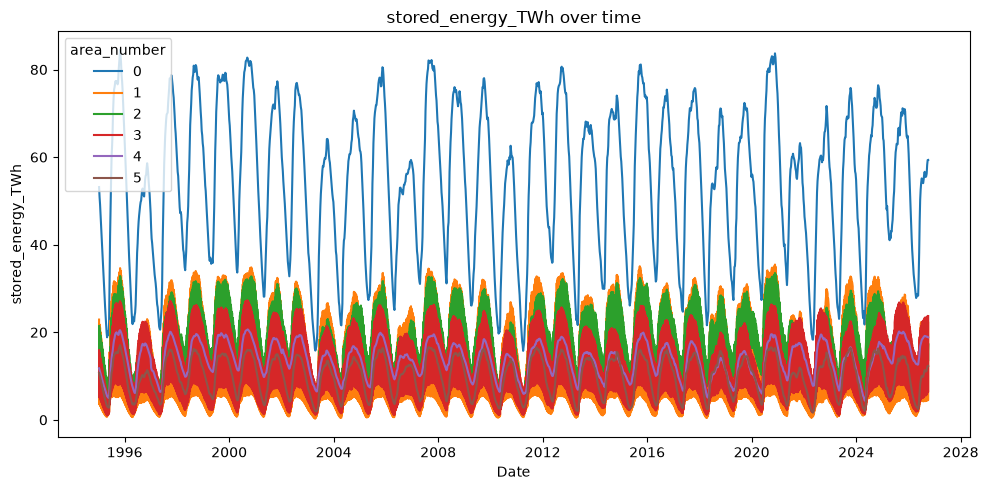

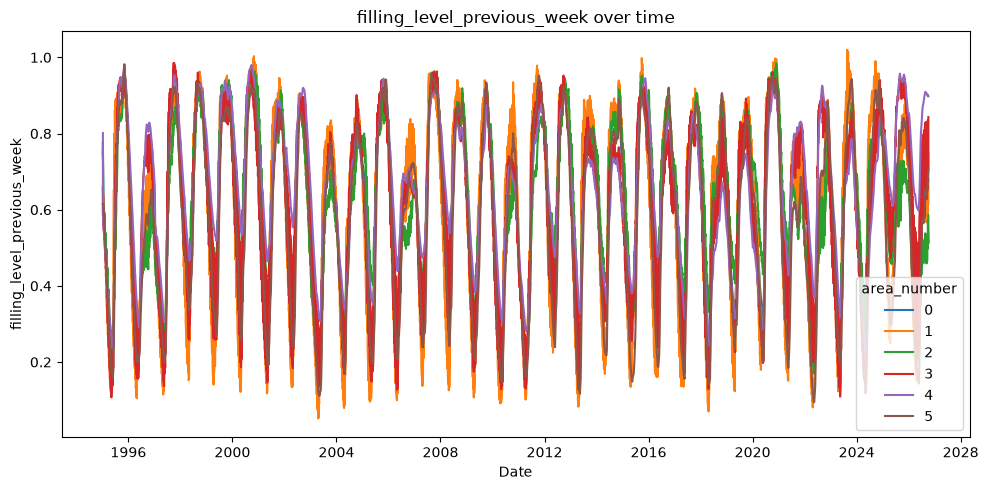

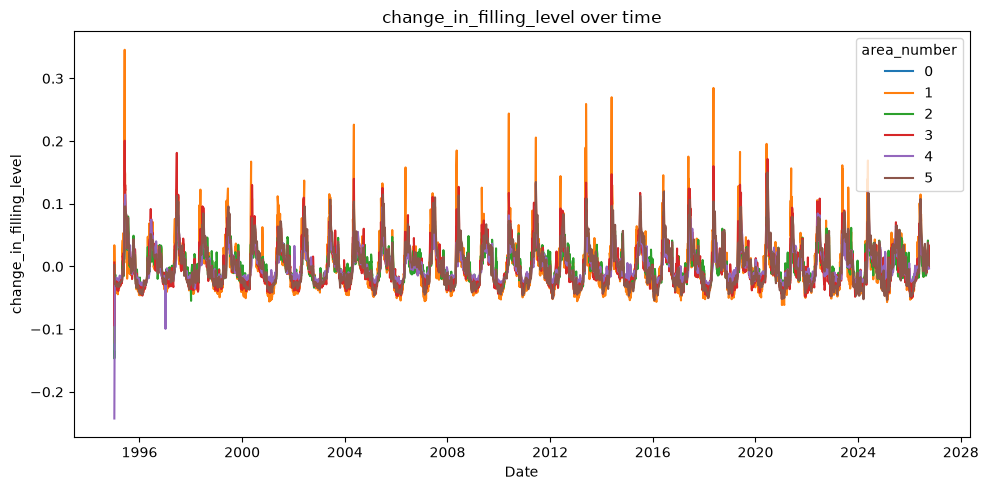

In [12]:
# numerical measurement columns 
line_cols = [
    "filling_level",
    "capacity_TWh",
    "stored_energy_TWh",
    "filling_level_previous_week",
    "change_in_filling_level"
]

# line plots
for col in line_cols:
    plt.figure(figsize=(10, 5))

    # Plot one line for each area number
    for area_number, group in df.groupby("area_number"):
        plt.plot(
            group["date"],
            group[col],
            label=area_number
        )

    plt.title(f"{col} over time")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.legend(title="area_number")
    plt.tight_layout()
    plt.show()

##### Distributions of categorical and discrete variables 

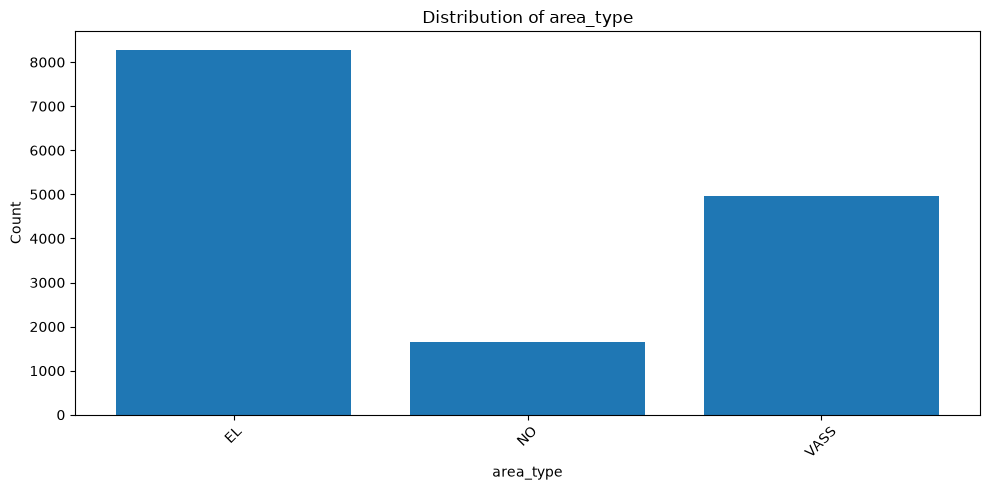

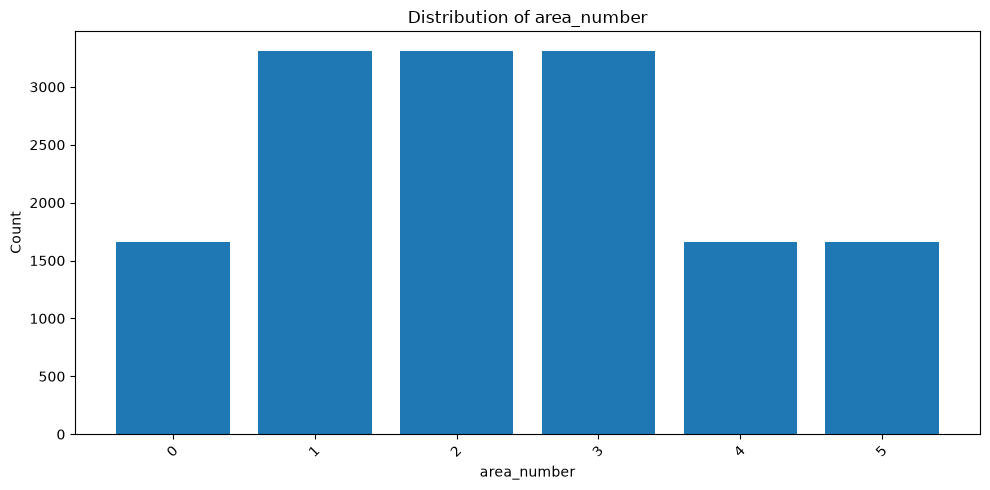

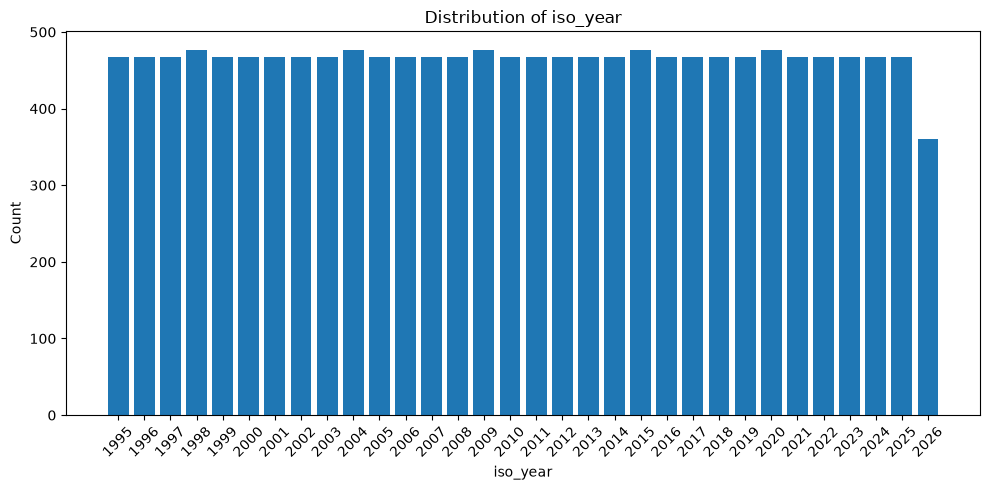

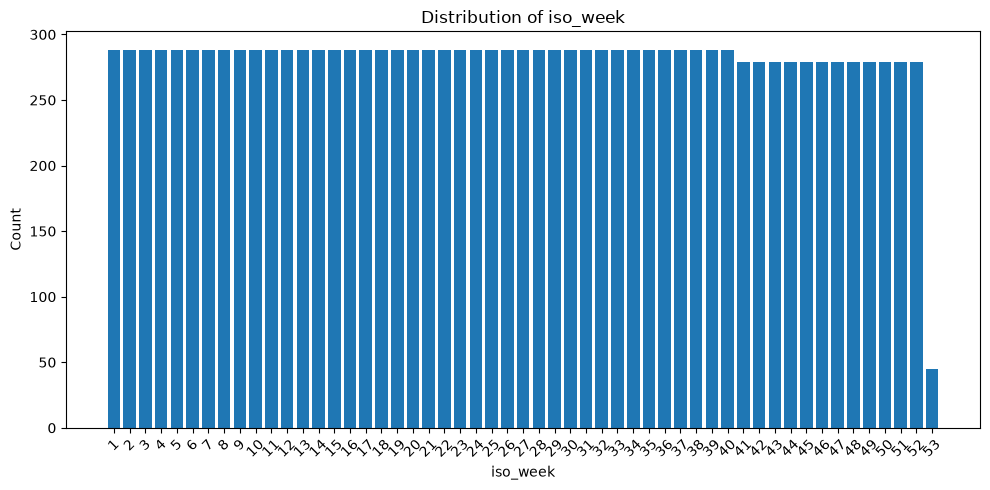

In [13]:
categorical_cols = [
    "area_type",
    "area_number",
    "iso_year",
    "iso_week"
]

for col in categorical_cols:
    # Count observations for each variable
    count_data = (
        df[col]
        .value_counts()
        .sort_index()
    )

    # Plot variable versus counts
    plt.figure(figsize=(10, 5))

    plt.bar(
        count_data.index.astype(str),
        count_data.values
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

#### Plot of all columns together 

In [14]:
measure_cols = [
    "filling_level",
    "capacity_TWh",
    "stored_energy_TWh",
    "filling_level_previous_week",
    "change_in_filling_level",
] 

# multiple observations for each date 
plot_data = df.groupby("date")[measure_cols].mean().reset_index() 


In [15]:
# Min-max scale each measurement column
for col in measure_cols:
    plot_data[col] = (
        (plot_data[col] - plot_data[col].min())
        / (plot_data[col].max() - plot_data[col].min())
    )

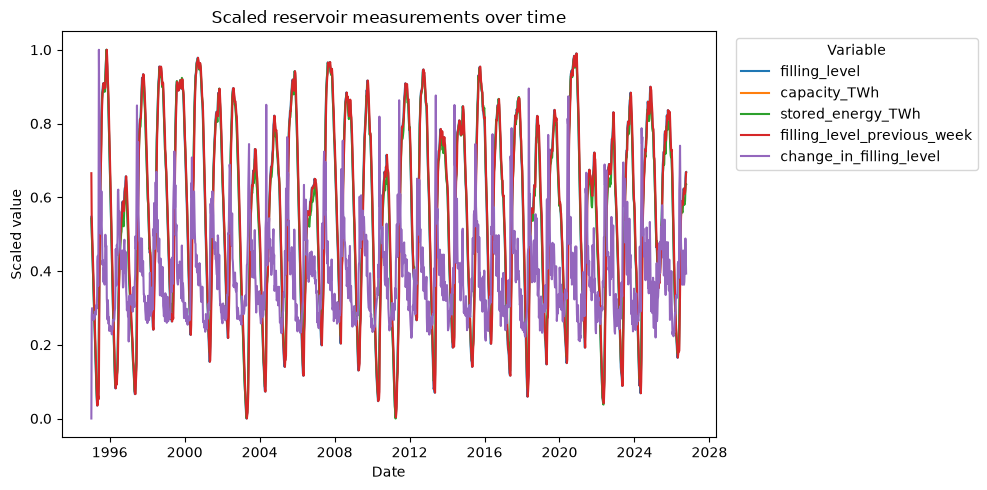

In [16]:
# line plot of all measurement columns
plt.figure(figsize=(10, 5))

for col in measure_cols:
    plt.plot(
        plot_data["date"],
        plot_data[col],
        label=col
    )

plt.title("Scaled reservoir measurements over time")
plt.xlabel("Date")
plt.ylabel("Scaled value")
plt.legend(
    title="Variable",
    bbox_to_anchor=(1.02, 1),
    loc="upper left")
plt.tight_layout()
plt.show()

##### Retrieving cross-border transfer from/to Norway for the last two years using ENTSO-E API 

In [17]:
# retrieving security token for entsoe API
key_path = Path("../No_sync/entsoe_api_key.txt")

with open(key_path, "r") as f:
    security_token = f.read().strip()

In [18]:
url_entsoe = "https://web-api.tp.entsoe.eu/api"

In [19]:
# Define the two-year period in two intervals
periods = [
    ("202410120000", "202510120000"),
    ("202510120000", "202610120000")
]

# Retrieve data for each year
for start, end in periods:

    # Define API request parameters
    params = {
        "securityToken": security_token,
        "documentType": "A11",
        "out_Domain": "10YNO-1--------2",  # Norway (NO1)
        "in_Domain": "10Y1001A1001A46L",   # Sweden (SE3)
        "periodStart": start,
        "periodEnd": end
    }

    # Send GET request to ENTSO-E API
    response = requests.get(url_entsoe, params=params)

    # Check if the request was successful
    print(response.status_code)

200
200


In [20]:
# List to store XML responses
responses = []

# Retrieve data for each year
for start, end in periods:

    # Update dates for each request
    params["periodStart"] = start
    params["periodEnd"] = end

    # Send GET request
    response = requests.get(url_entsoe, params=params)
    response.raise_for_status()

    # Store XML response
    responses.append(response.content)

    print(f"Retrieved data from {start} to {end}")

Retrieved data from 202410120000 to 202510120000
Retrieved data from 202510120000 to 202610120000


In [22]:
print(len(responses))

2


In [23]:
# Parse all XML responses
roots = []

for xml_data in responses:
    root = ET.fromstring(xml_data)
    roots.append(root)

In [24]:
# Select the first XML document
root = roots[0]

# Print root element
print(root.tag)

# Print child elements
for child in root:
    print(child.tag.split("}")[-1])

{urn:iec62325.351:tc57wg16:451-3:publicationdocument:7:0}Publication_MarketDocument
mRID
revisionNumber
type
sender_MarketParticipant.mRID
sender_MarketParticipant.marketRole.type
receiver_MarketParticipant.mRID
receiver_MarketParticipant.marketRole.type
createdDateTime
period.timeInterval
TimeSeries


In [25]:
# Define XML namespace
namespace = {"ns": root.tag.split("}")[0].strip("{")}

# Find all TimeSeries elements
time_series = root.findall("ns:TimeSeries", namespace)

print(f"Number of time series: {len(time_series)}")

Number of time series: 1


In [26]:
# Inspect the first TimeSeries
if time_series:
    for child in time_series[0]:
        print(child.tag.split("}")[-1])

mRID
businessType
in_Domain.mRID
out_Domain.mRID
quantity_Measure_Unit.name
curveType
Period
Period


In [ ]:
# convert the time series object into a pandas dataframe
data_list = []
for ts in time_series:
    # Extract relevant data from each TimeSeries
    period = ts.find("ns:Period", namespace)
    if period is not None:
        start = period.find("ns:timeInterval/ns:start", namespace).text
        end = period.find("ns:timeInterval/ns:end", namespace).text
        resolution = period.find("ns:resolution", namespace).text
        
        # Extract points
        points = period.findall("ns:Point", namespace)
        for point in points:
            position = point.find("ns:position", namespace).text
            quantity = point.find("ns:quantity", namespace).text
            
            # Append to data list
            data_list.append({
                "start": start,
                "end": end,
                "resolution": resolution,
                "position": position,
                "quantity": quantity
            })
